In [1]:
!wget -O credit.zip "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
!unzip -o credit.zip
!pip install xlrd -q
!ls

--2026-11-14 19:56:13--  https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘credit.zip’

credit.zip              [   <=>              ]   5.28M  11.2MB/s    in 0.5s    

2026-11-14 19:56:14 (11.2 MB/s) - ‘credit.zip’ saved [5539494]

Archive:  credit.zip
 extracting: default of credit card clients.xls  
 credit.zip  'default of credit card clients.xls'   sample_data


In [2]:
import pandas as pd
df = pd.read_excel("default of credit card clients.xls", header=1)
df = df.rename(columns={"default payment next month": "default", "PAY_0": "PAY_1"})
df = df.drop(columns=["ID"])
print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
# Education has undocumented codes 0, 5, 6 -> group them with "others" (4)
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
# Marriage has an undocumented 0 -> group with "others" (3)
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print(df.isnull().sum().sum())   # should be 0, no missing values
print(df["default"].value_counts(normalize=True))   # about 22% defaulters

0
default
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [4]:
pay_cols = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

df["AvgDelay"] = df[pay_cols].mean(axis=1)
df["MaxDelay"] = df[pay_cols].max(axis=1)
df["MonthsLate"] = (df[pay_cols] > 0).sum(axis=1)
df["AvgBill"] = df[bill_cols].mean(axis=1)
df["TotalPaid"] = df[amt_cols].sum(axis=1)
df["Utilization"] = df["AvgBill"] / df["LIMIT_BAL"]
df["PayRatio"] = df["TotalPaid"] / (df[bill_cols].sum(axis=1).abs() + 1)

In [5]:
X = df.drop("default", axis=1)
y = df["default"]

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("default", axis=1)
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train_s.shape, X_test_s.shape)

(24000, 30) (6000, 30)


In [8]:
print(df.shape)
print(df.isnull().sum().sum())   # should be 0
print(X_train_s.shape, y_train.shape)

(30000, 31)
0
(24000, 30) (24000,)


/tmp/ipykernel_2061/908915638.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.title("ROC Curves"); plt.legend(); plt.show()


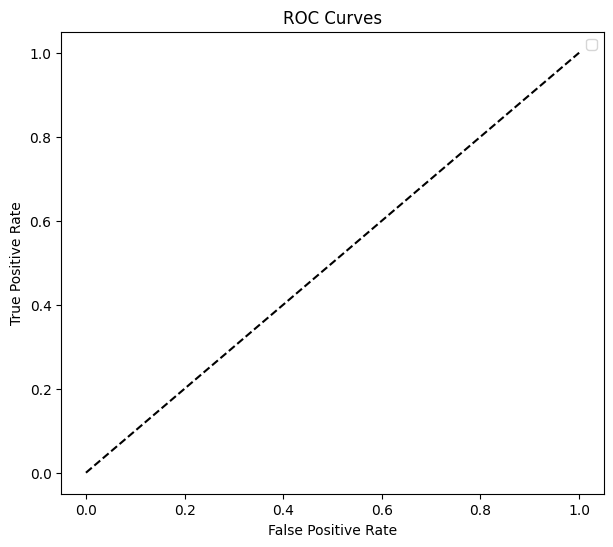

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# ROC curves, all models on one plot
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.show()

In [11]:
print(list(probas.keys()))

[]


trained: Logistic Regression
trained: Decision Tree
trained: Random Forest


,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.443,0.602,0.511,0.745
1,Decision Tree,0.450,0.638,0.527,0.766
2,Random Forest,0.483,0.607,0.538,0.776


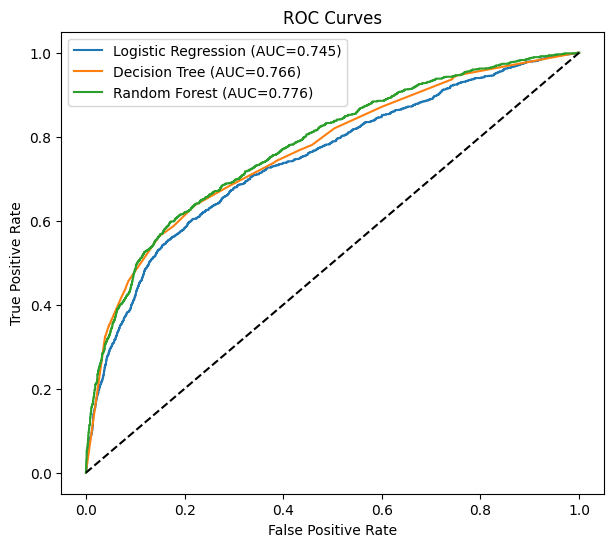

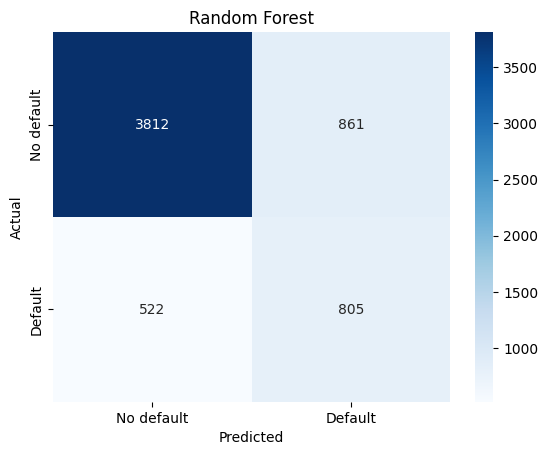

Best model: Random Forest
              precision    recall  f1-score   support

           0       0.88      0.82      0.85      4673
           1       0.48      0.61      0.54      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.77      0.78      6000



In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)

# 1. Create AND train the models
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=200,
                                            max_depth=8, n_jobs=-1, random_state=42),
}

results, probas = [], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)            # <- training happens here
    pred = model.predict(X_test_s)
    probas[name] = model.predict_proba(X_test_s)[:, 1]
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
    })
    print("trained:", name)

results_df = pd.DataFrame(results).round(3)
display(results_df)

# 2. ROC curves
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.show()

# 3. Confusion matrix for the best model
best_name = results_df.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best = models[best_name]
pred = best.predict(X_test_s)
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No default", "Default"], yticklabels=["No default", "Default"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(best_name); plt.show()
print("Best model:", best_name)
print(classification_report(y_test, pred))

In [14]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [6, 8, 10, 12],
    "min_samples_leaf": [1, 5, 10, 20],
}
search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
    param_dist, n_iter=8, scoring="roc_auc", cv=3, random_state=42, n_jobs=-1)
search.fit(X_train_s, y_train)

print("Best params:", search.best_params_)
print("CV AUC:", round(search.best_score_, 3))

tuned = search.best_estimator_
tuned_proba = tuned.predict_proba(X_test_s)[:, 1]
tuned_pred = tuned.predict(X_test_s)
print("Test AUC:", round(roc_auc_score(y_test, tuned_proba), 3))
print("Precision:", round(precision_score(y_test, tuned_pred), 3),
      "| Recall:", round(recall_score(y_test, tuned_pred), 3),
      "| F1:", round(f1_score(y_test, tuned_pred), 3))

Best params: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 8}
CV AUC: 0.783
Test AUC: 0.777
Precision: 0.48 | Recall: 0.616 | F1: 0.54


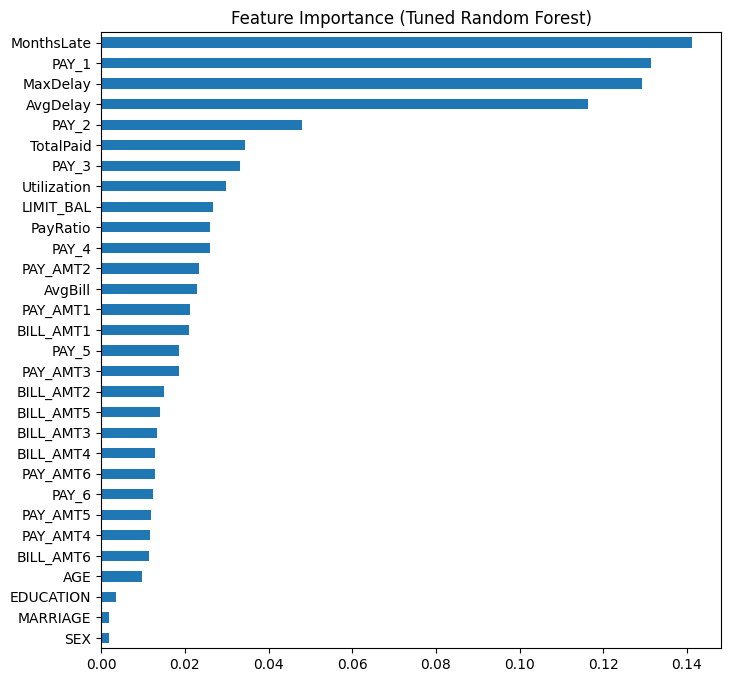

In [15]:
imp = pd.Series(tuned.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 8), title="Feature Importance (Tuned Random Forest)")
plt.show()

In [16]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (tuned_proba >= t).astype(int)
    print(f"threshold={t}: precision={precision_score(y_test, p):.2f}, "
          f"recall={recall_score(y_test, p):.2f}, f1={f1_score(y_test, p):.2f}")

threshold=0.3: precision=0.31, recall=0.86, f1=0.45
threshold=0.4: precision=0.40, recall=0.71, f1=0.51
threshold=0.5: precision=0.48, recall=0.62, f1=0.54
threshold=0.6: precision=0.55, recall=0.52, f1=0.54
threshold=0.7: precision=0.62, recall=0.40, f1=0.49


In [17]:
import joblib
joblib.dump(tuned, "credit_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']